# Python Programming - In-Class Assignment


Import necessary libraries and load the data

From kaggle (https://www.kaggle.com/datasets/yasserh/titanic-dataset):
The sinking of the Titanic is one of the most infamous shipwrecks in history.

On April 15, 1912, during her maiden voyage, the widely considered “unsinkable” RMS Titanic sank after colliding with an iceberg. Unfortunately, there weren't enough lifeboats for everyone on board, resulting in the death ofmore than half of the passengers and crew.

While there was some element of luck involved in surviving, it seems some groups of people were more likely to survive than others.

This exercise seeks to explore the factors that appeared to influence survival.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the 'titanic' dataset from seaborn
titanic_data = sns.load_dataset('titanic')

display(titanic_data.head())
print(titanic_data.shape)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


(891, 15)


Task 1: Calculate overall survival rate.

Hint: becausse 'survived' is 0 and 1, survival rate can be computed as the .mean() of that column

In [ ]:
# Calculate overall survival rate
survival_rate = titanic_data["survived"].mean()
print(survival_rate)

0.3838383838383838


Task 2: Calculate and print the survival rates by gender/sex ('sex'), passenger class ('class'), and embarkation point ('embarked'; the location where the journey began).

Hint: the material showed us how to filter material, which can work here. Pandas dataframes also offers a convenient function groupby, that will take a one or a list of columns, and group the data by the values of that/those column(s). Operations (such as .mean()) on the returned item will be performed on each group.

In [ ]:
# Calculate survival rates by gender and visualize it
survival_by_sex = titanic_data.groupby('sex')['survived'].mean()
print(survival_by_sex)


sex
female    0.742038
male      0.188908
Name: survived, dtype: float64


In [ ]:
# Calculate survival rates by passenger class and visualize it
survival_by_pclass = titanic_data.groupby('pclass')['survived'].mean()
print(survival_by_pclass)

pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


In [ ]:
# Calculate survival rates by embarkation point and visualize it
survival_by_embarked = titanic_data.groupby('embarked')['survived'].mean()
print(survival_by_embarked)

embarked
C    0.553571
Q    0.389610
S    0.336957
Name: survived, dtype: float64


Task 3: Calculate the survival rate by age group (under 12 as child, 13-20 as teen, 21-40 as adult, 41-60 as middle-aged, above 61 as senior).

In [ ]:
# create a new column age_group based on the criteria above
bins = [0, 12, 20, 40, 60, np.inf]
labels = ['child', 'teen', 'adult', 'middle-aged', 'senior']

titanic_data['age_group'] = pd.cut(titanic_data['age'], bins=bins, labels=labels, include_lowest=True)


# Calculate survival rates by age group

survival_by_age = titanic_data.groupby('age_group', observed=True)['survived'].agg(['count', 'mean'])
survival_by_age.columns = ['passengers', 'survival_rate']
survival_by_age['survival_rate'] = (survival_by_age['survival_rate'] * 100).round(1)
print(survival_by_age)

             passengers  survival_rate
age_group                             
child                69           58.0
teen                110           38.2
adult               385           39.7
middle-aged         128           39.1
senior               22           22.7


Task 4: Create a box plot for age distribution by survival.

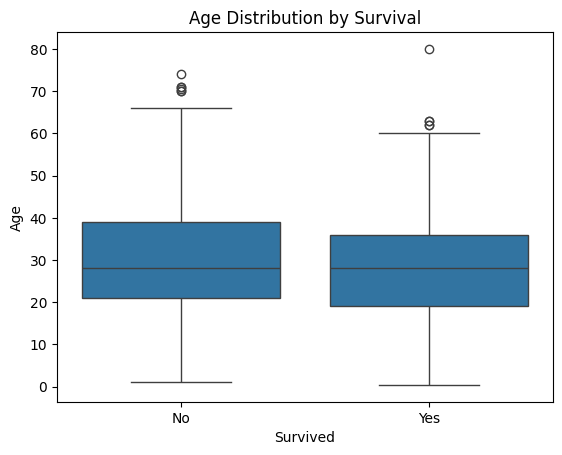

In [ ]:
# Create a box plot for age distribution by survival
df = sns.load_dataset('titanic')

ax = sns.boxplot(data=df, x='survived', y='age')
ax.set_title('Age Distribution by Survival')
ax.set_xlabel('Survived')
ax.set_ylabel('Age')
ax.set_xticks([0, 1])
ax.set_xticklabels(['No', 'Yes'])
plt.show()

Task 5: Create a stacked bar chart to visualize the distribution of Titanic passengers by class, using different colors to represent survival status within each class.
Hint: try creating a comment to do this one and use the AI to help. What is this code doing?

alive    no  yes
class           
First    80  136
Second   97   87
Third   372  119


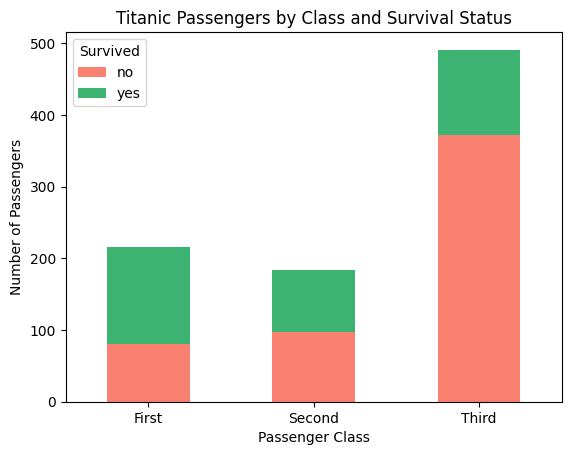

In [ ]:
import matplotlib.pyplot as plt

# Create a stacked bar chart to visualize the distribution of Titanic passengers by class
df = sns.load_dataset('titanic')

# Count passengers in each class, split by survival status
counts = pd.crosstab(df['class'], df['alive'])
print(counts)

# Stacked bar chart
ax = counts.plot(kind='bar', stacked=True, color=['salmon', 'mediumseagreen'])
ax.set_title('Titanic Passengers by Class and Survival Status')
ax.set_xlabel('Passenger Class')
ax.set_ylabel('Number of Passengers')
ax.legend(title='Survived')
plt.xticks(rotation=0)
plt.show()

**Open-Ended Questions:** From our analysis, some more in-depth questions can be raised. Please discuss and attempt to answer them by using Python to perform data analysis and visualizations to support your claims. Keep in mind that there are no definitive answers to these questions.

Question 1: Given, from task 2, the survival rates by embarkation point are as follows:

| Embarkation Point | Survival Rate (%) |
|-------------------|--------------------|
| C                 | 55.36              |
| Q                 | 38.96              |
| S                 | 33.70              |

does this indicate that, if you will be on the Titanic, better to select Port C as your embarkation point for increasing the chances of survival?

Although the data shows that passengers with Port C as their embarkation point have a higher survival rate (55.36>28.96>33.7), this correlation does not mean that embarking from Port C gives you a higher chance of survival. Other factors may be at play like sex and pclass that impact survival rate.

**Your Q1 discussion here:**

In [ ]:
# Optional: if you have code to support your Q1 discussion, please add it here.
survival_by_sex = titanic_data.groupby('sex')['survived'].mean()
print(survival_by_sex)

Question 2: Given, from task 3, the survival rates by age group are as follows:

| Age Group | Survival Rate (%) |
|-----------|--------------------|
| Child     | 57.97              |
| Teen      | 38.18              |
| Adult     | 39.74              |
| Middle-Aged| 39.06              |
| Senior    | 22.73              |

Does this indicate that senior passengers were less taken care of?

The data above doesn't necessarily indicate senior passengers were less taken care of because there are only a few data values for senior passengers as indicated by the code below. In addition, women and children have a high survival rate as indicated by other data analysis. Because most seniors were male, the low senior survival rate may be a reflection of the "women and children first" procedure, not necessarily seniors last.

**Your Q2 discussion here:**

In [ ]:
# Optional: if you have code to support your Q2 discussion, please add it here.
from google.colab import drive
drive.mount('/content/drive')

!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/In_Class_Assignment_4_python.ipynb"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/In_Class_Assignment_4_python.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 374968 bytes to /content/drive/MyDrive/Colab Notebooks/In_Class_Assignment_4_python.html


When you are done, make sure to submit your assignments in accordance with the instructions on canvas.